In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from typing import Dict, Tuple
import seaborn as sns
from loader_compute_rates import DSMCDataProcessor

sns.set_theme(style="whitegrid", context="talk")

In [2]:
def load_and_process_data(paths: Dict[str, str]) -> Tuple[Dict[str, DSMCDataProcessor], Dict[str, np.ndarray]]:
    processors = {}
    heating_rates = {}

    for key, path in paths.items():
        processor = DSMCDataProcessor(path)
        processor.load_parameters()
        processor.load_data()
        processors[key] = processor
        heating_rates[key] = processor.compute_heating_rate()

    return processors, heating_rates


# Define the paths for the datasets
data_paths = {
    "400up": "/mnt/performance/bridges-project/Results_20250131_035006",
    "450up": "/media/astrojose/AstroBook/ArchiveSims/Results_20250131_160314.022",
    "500up": "/media/astrojose/AstroBook/ArchiveSims/Results_20250203_210518.290",
    "600up": "/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212245.806",
    "700up": "/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212248.321",
    "800up": "/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212249.591",
    "900up": "/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212232.422",
}

# Load and process the data
processors, heating_rates = load_and_process_data(data_paths)

Text(0.95, 0.05, 'Ballistic Upper Bound\n where $\\Delta T = T - 270$')

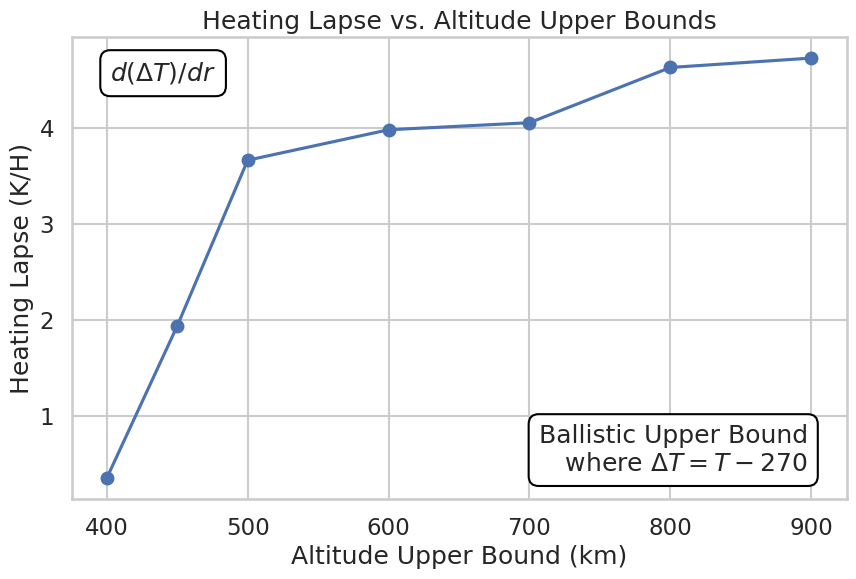

In [3]:
# Extract the second values from the heating rates
second_values = [heating_rates[key][1] for key in sorted(heating_rates.keys())]

# Extract just the numbers from the keys for x-axis
altitudes = [int(key.replace("up", "")) for key in sorted(heating_rates.keys())]

plt.figure(figsize=(10, 6))
plt.plot(altitudes, second_values, marker="o")
plt.xlabel("Altitude Upper Bound (km)")
plt.ylabel("Heating Lapse (K/H)")
plt.title("Heating Lapse vs. Altitude Upper Bounds")


# Add boxed text with manual underline
ax = plt.gca()
text = ax.text(
    0.05,
    0.95,
    r"$d(\Delta T) / dr$",  # Regular LaTeX without underline
    bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": "black", "pad": 0.4},
    transform=ax.transAxes,
    ha="left",
    va="top",
)

ax.text(
    0.95,
    0.05,
    "Ballistic Upper Bound\n where $\\Delta T = T - 270$",
    bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": "black", "pad": 0.4},
    transform=ax.transAxes,
    ha="right",
    va="bottom",
)

150 km - 320 km | exobase at 220km 

In [4]:
new_data_paths = {
    "20250204_015519.338": "/media/astrojose/AstroBook/ArchiveSims/Results_20250204_015519.338",
    "20250204_015818.840": "/media/astrojose/AstroBook/ArchiveSims/Results_20250204_015818.840",
    "20250204_015758.213": "/media/astrojose/AstroBook/ArchiveSims/Results_20250204_015758.213",
    "20250131_212248.321": "/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212248.321",
}

processors_new, heating_rates_new = load_and_process_data(new_data_paths)

In [5]:
[processors_new[k].params.radial_cells[-1] for k in processors_new.keys()]

[np.float64(706.5703224440149),
 np.float64(703.3491021279592),
 np.float64(702.5037024331691),
 np.float64(699.9371222678656)]

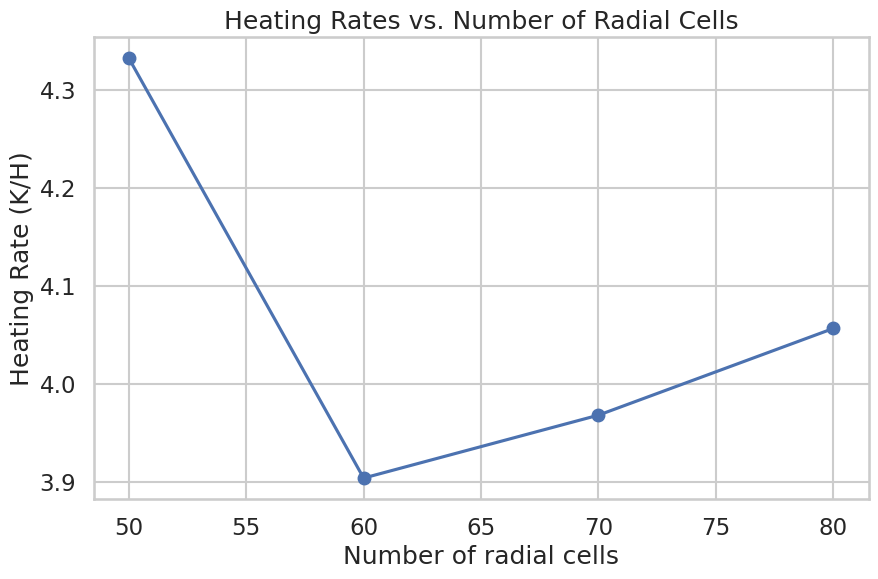

In [6]:
# Compute the number of radial cells for each processor (sorted by key)
radial_lengths = [len(processors_new[key].params.radial_cells) for key in sorted(processors_new.keys())]

# Extract the heating rates (using the second element from each tuple as before)
heating_values = [heating_rates_new[key][1] for key in sorted(heating_rates_new.keys())]

sorted_pairs = sorted(zip(radial_lengths, heating_values))
x_sorted, y_sorted = zip(*sorted_pairs)

plt.figure(figsize=(10, 6))
plt.plot(x_sorted, y_sorted, marker="o")
plt.xlabel("Number of radial cells")
plt.ylabel("Heating Rate (K/H)")
plt.title("Heating Rates vs. Number of Radial Cells")
plt.show()


In [7]:
import sqlite3

db_path = "/media/astrojose/AstroBook/ArchiveSims/simulation_metadata.db"  # update as needed
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

query = "SELECT data_path FROM simulation_runs WHERE rmax BETWEEN 400 AND 1000 AND sim_params_id = 22"
cursor.execute(query)

results = cursor.fetchall()
for row in results:
    print(row)

conn.close()


# Create a dictionary mapping a simplified name (using the last part of the path) to the data path
query_paths = {row[0].split("/")[-1]: row[0] for row in results}

# Process the data using the existing load_and_process_data function
processors_query, heating_rates_query = load_and_process_data(query_paths)

# Optionally, print the resulting heating rates for verification
print(heating_rates_query)

('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_023428',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_035006',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_050914',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_050925',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_050926.563',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_050926',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_160314.022',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_172547.105',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212232.422',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212245.806',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212248.321',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212249.591',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250203_210518.290',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250203_210847.474',)
('/media/ast

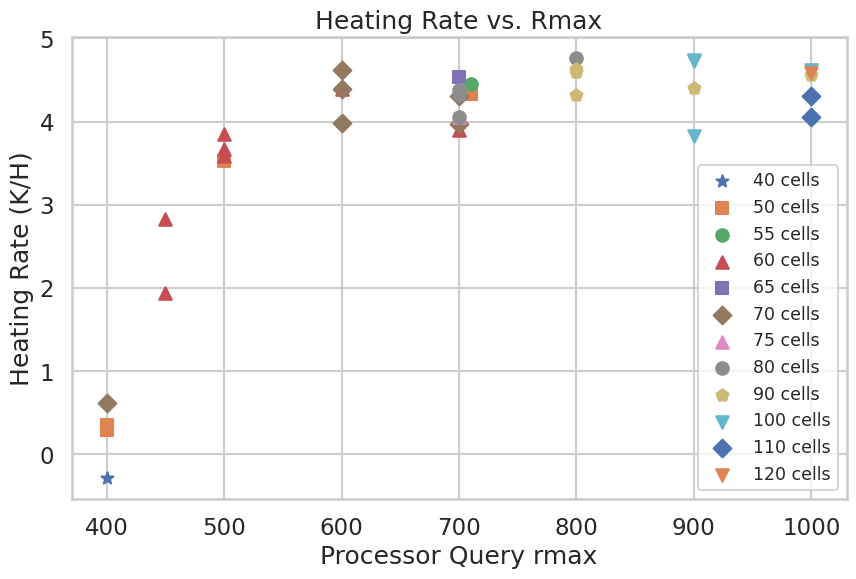

In [8]:
# Define marker types to cycle through
marker_types = ["o", "s", "^", "D", "v", "p", "*"]
marker_dict = {}

# Collect data points with rmax, heating_rate, and radial cell count
data_points = []
for key, processor in processors_query.items():
    if key in heating_rates_query:
        rmax = processor.params.rmax
        heating_rate = heating_rates_query[key][1]
        radial_count = len(processor.params.radial_cells)
        # Assign a marker for this radial_count if not already mapped
        if radial_count not in marker_dict:
            marker_dict[radial_count] = marker_types[len(marker_dict) % len(marker_types)]
        data_points.append((rmax, heating_rate, radial_count))

# Plot points grouped by radial cell count with the associated marker
plt.figure(figsize=(10, 6))
unique_counts = sorted({dp[2] for dp in data_points})
for count in unique_counts:
    xs = [r for r, hr, rc in data_points if rc == count]
    ys = [hr for r, hr, rc in data_points if rc == count]
    plt.scatter(xs, ys, marker=marker_dict[count], label=f"{count} cells")

plt.xlabel("Processor Query rmax")
plt.ylabel("Heating Rate (K/H)")
plt.title("Heating Rate vs. Rmax")
plt.legend(fontsize="x-small")
plt.show()

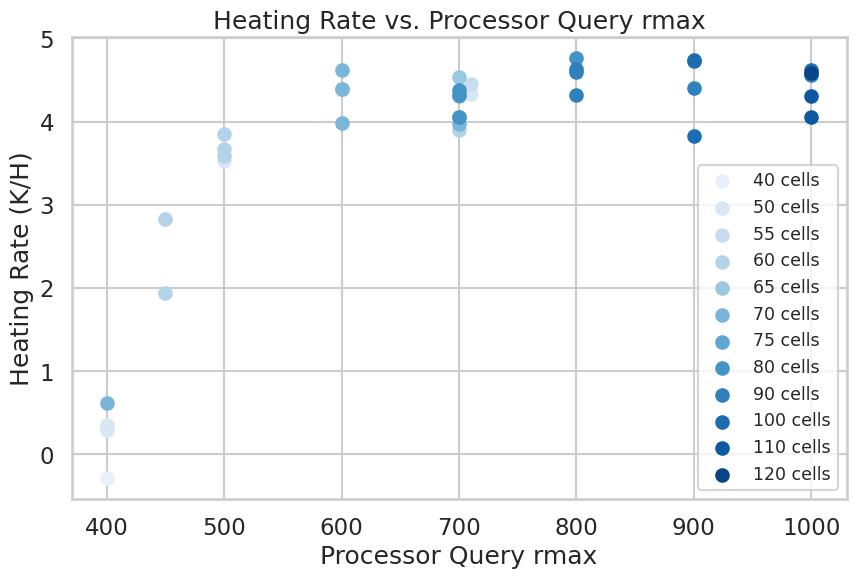

In [9]:
# Collect data points with rmax, heating_rate, and radial cell count
data_points = []
for key, processor in processors_query.items():
    if key in heating_rates_query:
        rmax = processor.params.rmax
        heating_rate = heating_rates_query[key][1]
        radial_count = len(processor.params.radial_cells)
        data_points.append((rmax, heating_rate, radial_count))

# Create a sequential color palette based on unique radial cell counts
unique_counts = sorted({dp[2] for dp in data_points})
colors = sns.color_palette("Blues", n_colors=len(unique_counts))
color_dict = {count: color for count, color in zip(unique_counts, colors)}

# Plot points grouped by radial cell count with the associated color
plt.figure(figsize=(10, 6))
for count in unique_counts:
    xs = [r for r, hr, rc in data_points if rc == count]
    ys = [hr for r, hr, rc in data_points if rc == count]
    plt.scatter(xs, ys, color=color_dict[count], label=f"{count} cells")

plt.xlabel("Processor Query rmax")
plt.ylabel("Heating Rate (K/H)")
plt.title("Heating Rate vs. Processor Query rmax")
plt.legend(fontsize="x-small")
plt.show()


('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_074359.293',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_074640.207',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_075200.674',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_080020.535',)
Results_20250209_074359.293: 100 cells, Heating Rate: 4.621864722975862
Results_20250209_074640.207: 110 cells, Heating Rate: 4.3132023963457735
Results_20250209_075200.674: 120 cells, Heating Rate: 4.582485375603017
Results_20250209_080020.535: 90 cells, Heating Rate: 4.55547264993207


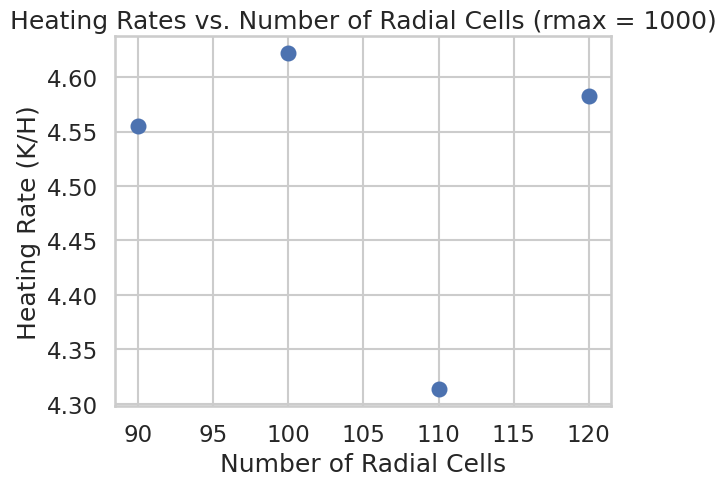

In [10]:
# New query: Filter simulation runs from the database with rmax exactly equal to 1000
db_conn = sqlite3.connect(db_path)
db_cursor = db_conn.cursor()

sim_query = "SELECT data_path FROM simulation_runs WHERE rmax = 1000 AND UBC = '' AND sim_params_id = 22"
db_cursor.execute(sim_query)
sim_result_rows = db_cursor.fetchall()
for sim_row in sim_result_rows:
    print(sim_row)
db_conn.close()

# Create a dictionary mapping simplified simulation names to complete paths
sim_paths_1000 = {sim_row[0].split("/")[-1]: sim_row[0] for sim_row in sim_result_rows}

# Process the simulation data using the existing load_and_process_data function
sim_processors_1000, sim_heating_rates_1000 = load_and_process_data(sim_paths_1000)

# Filter and plot simulations with rmax equal to 1000
radial_cell_counts = []  # store the number of radial cells
sim_heating_values = []  # store the heating rate (second element)

for sim_key, sim_proc in sim_processors_1000.items():
    if sim_proc.params.rmax == 1000:
        num_cells = len(sim_proc.params.radial_cells)
        rate_value = sim_heating_rates_1000[sim_key][1]
        radial_cell_counts.append(num_cells)
        sim_heating_values.append(rate_value)
        print(f"{sim_key}: {num_cells} cells, Heating Rate: {rate_value}")

if radial_cell_counts and sim_heating_values:
    plt.scatter(radial_cell_counts, sim_heating_values, color="b", s=100)
    plt.xlabel("Number of Radial Cells")
    plt.ylabel("Heating Rate (K/H)")
    plt.title("Heating Rates vs. Number of Radial Cells (rmax = 1000)")
    plt.show()
else:
    print("No simulations with rmax == 1000 were found.")

('/media/astrojose/AstroBook/ArchiveSims/Results_20250131_212248.321',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250204_013656.592',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250204_015519.338',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250204_015758.213',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250204_015818.840',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_072324.186',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_073738.002',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_073739.248',)
Results_20250131_212248.321: 80 cells, Heating Rate: 4.0566107844864305
Results_20250204_013656.592: 70 cells, Heating Rate: 4.308399231906559
Results_20250204_015758.213: 70 cells, Heating Rate: 3.9681351112127516
Results_20250204_015818.840: 60 cells, Heating Rate: 3.903888194635871
Results_20250209_073738.002: 65 cells, Heating Rate: 4.530722267631306
Results_20250209_073739.248: 75 cells, Heating Rate: 4.058328128552

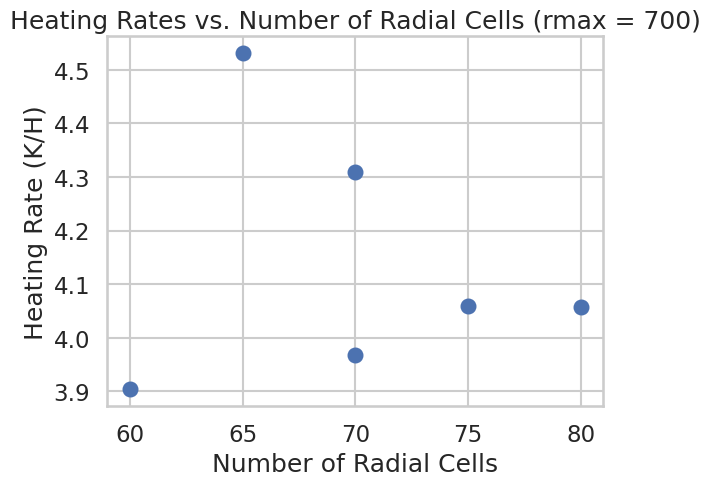

In [11]:
# New query: Filter simulation runs from the database with rmax exactly equal to 700
db_conn = sqlite3.connect(db_path)
db_cursor = db_conn.cursor()

sim_query = "SELECT data_path FROM simulation_runs WHERE rmax BETWEEN 690 AND 720 AND UBC = '' AND sim_params_id = 22 AND avg_total_particles > 1000000"
db_cursor.execute(sim_query)
sim_result_rows = db_cursor.fetchall()
for sim_row in sim_result_rows:
    print(sim_row)
db_conn.close()

# Create a dictionary mapping simplified simulation names to complete paths
sim_paths_700 = {sim_row[0].split("/")[-1]: sim_row[0] for sim_row in sim_result_rows}

# Process the simulation data using the existing load_and_process_data function
sim_processors_700, sim_heating_rates_700 = load_and_process_data(sim_paths_700)

# Filter and plot simulations with rmax equal to 700
radial_cell_counts = []  # store the number of radial cells
sim_heating_values = []  # store the heating rate (second element)

for sim_key, sim_proc in sim_processors_700.items():
    if sim_proc.params.rmax == 700:
        num_cells = len(sim_proc.params.radial_cells)
        rate_value = sim_heating_rates_700[sim_key][1]
        radial_cell_counts.append(num_cells)
        sim_heating_values.append(rate_value)
        print(f"{sim_key}: {num_cells} cells, Heating Rate: {rate_value}")

if radial_cell_counts and sim_heating_values:
    plt.scatter(radial_cell_counts, sim_heating_values, color="b", s=100)
    plt.xlabel("Number of Radial Cells")
    plt.ylabel("Heating Rate (K/H)")
    plt.title("Heating Rates vs. Number of Radial Cells (rmax = 700)")
    plt.show()
else:
    print("No simulations with rmax == 700 were found.")

In [12]:
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Query simulation runs where UBC equals 'UBC_FREE_ESCAPE'
query = "SELECT data_path FROM simulation_runs WHERE UBC = 'UBC_FREE_ESCAPE' AND sim_params_id = 22"
cursor.execute(query)

results = cursor.fetchall()
for row in results:
    print(row)

conn.close()

# Create a dictionary mapping a simplified name (using the last part of the path) to the data path
query_paths_ubc = {row[0].split("/")[-1]: row[0] for row in results}

# Process the data using the existing load_and_process_data function
processors_query_ubc, heating_rates_query_ubc = load_and_process_data(query_paths_ubc)

('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_082751.628',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_083703.976',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_083945.992',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_084356.301',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_084527.010',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_085818.265',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_232726.097',)
('/media/astrojose/AstroBook/ArchiveSims/Results_20250209_232840.306',)


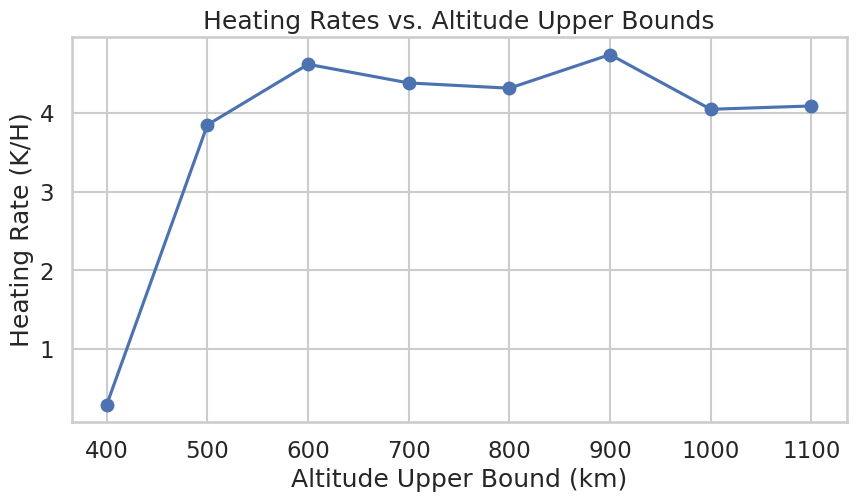

In [13]:
# Extract the second values from the heating rates
heating_rates_ubc_escape = [heating_rates_query_ubc[key][1] for key in sorted(heating_rates_query_ubc.keys())]

# Extract the upper altitdue bounds from the keys for x-axis
altitudes_ubc_escape = [processors_query_ubc[key].params.rmax for key in sorted(heating_rates_query_ubc.keys())]


# plot the heating rates vs upper bound altitudes
plt.figure(figsize=(10, 5))
plt.plot(altitudes_ubc_escape, heating_rates_ubc_escape, marker="o", linestyle="-")
plt.xlabel("Altitude Upper Bound (km)")
plt.ylabel("Heating Rate (K/H)")
plt.title("Heating Rates vs. Altitude Upper Bounds")
plt.show()

In [14]:
# # Loop through processors_query_ubc to find the processor with rmax equal to 900
# processor_900: DSMCDataProcessor = None
# for key, proc in processors_query_ubc.items():
#     if proc.params.rmax == 900.0:
#         processor_900 = proc
#         print(f"Processor found for key {key}: {processor_900}")
#         break

In [15]:
processor_900 = processors["800up"]

In [16]:
processor_900._find_stable_period(processor_900.temperature_data)

40

In [17]:
wave_indices = processor_900.get_wave_time_indices()

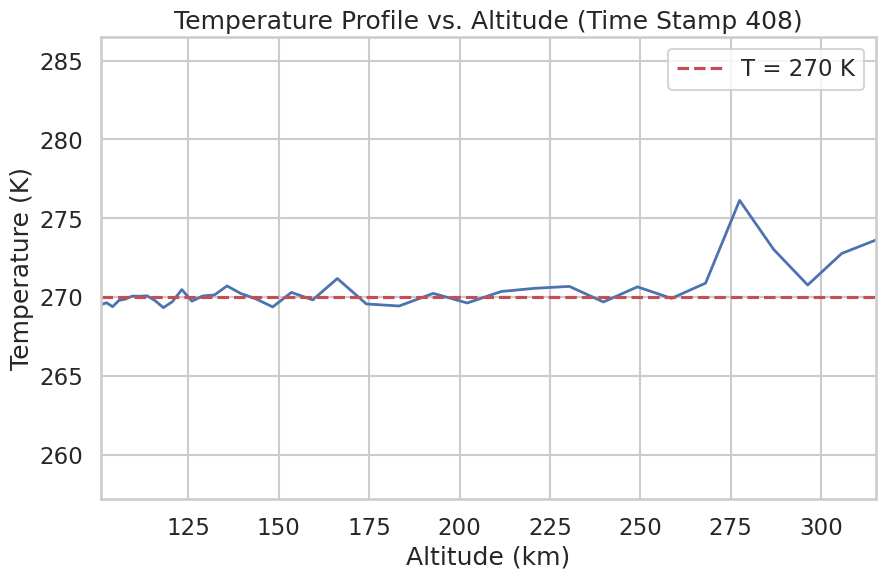

In [18]:
import matplotlib.animation as animation

# Extract altitude and temperature data arrays
altitude = np.array(processor_900.params.radial_cells)
temperature = np.array(processor_900.temperature_data[wave_indices[0]])

fig, ax = plt.subplots(figsize=(10, 6))
(line,) = ax.plot([], [], lw=2)

# Use only the altitudes below 320 km for the plot
mask = altitude < 320
ax.set_xlim(altitude[mask].min(), altitude[mask].max())

# Pre-compute temperature limits over all frames to set the y-axis properly.
# Here we sample 50 time indices evenly up to wave_indices[0]
time_indices = np.linspace(0, int(wave_indices[0]), 50, dtype=int)
all_temps = [np.array(processor_900.temperature_data[t])[mask] for t in time_indices]
ymin = min(temp.min() for temp in all_temps) - 5
ymax = max(temp.max() for temp in all_temps) + 5
ax.set_ylim(ymin, ymax)

ax.set_xlabel("Altitude (km)")
ax.set_ylabel("Temperature (K)")
ax.set_title("Temperature Profile vs. Altitude")
ax.axhline(y=270, color="r", linestyle="--", label="T = 270 K")
ax.legend()


def init():
    line.set_data([], [])
    return (line,)


def animate(i):
    t_idx = time_indices[i]
    temp = np.array(processor_900.temperature_data[t_idx])
    line.set_data(altitude[mask], temp[mask])
    ax.set_title(f"Temperature Profile vs. Altitude (Time Stamp {t_idx})")
    return (line,)


ani = animation.FuncAnimation(fig, animate, frames=len(time_indices), init_func=init, blit=True, repeat=True)
# save the animation
ani.save("temperature_profile.mp4", writer="ffmpeg", fps=5)

In [19]:
# Calculate the median absolute deviation (MAD) of temperatures at the altitude closest to 230 km,
# considering only time frames before wave_indices[0].

# Get the altitudes corresponding to the masked region (altitudes < 320 km)
alt_mask = altitude[mask]

# Find the index of the altitude value closest to 230 km.
idx = np.abs(alt_mask - 230).argmin()

# Extract temperature values at the chosen altitude from time frames before wave_indices[0].
temps_at_230 = np.array(
    [np.array(processor_900.temperature_data[t])[mask][idx] for t in range(350, int(wave_indices[0]))]
)

# Compute the median and then the MAD.
median_temp = np.median(temps_at_230)
mad = np.median(np.abs(temps_at_230 - median_temp))

print("MAD near altitude 230 (before wave_indices[0]):", mad)
median_temp

MAD near altitude 230 (before wave_indices[0]): 0.6067151159136301


np.float64(270.8327448787032)

In [20]:
wave_indices[0]

np.int64(408)

In [21]:
# First, extract the temperature time series at altitude 230 km (for the masked data)
alt_mask = altitude[mask]
idx = np.abs(alt_mask - 230).argmin()

temps = np.array([np.array(processor_900.temperature_data[t])[mask][idx] for t in range(1, int(wave_indices[0]))])


def rolling_mad(data, window_size):
    """
    Compute the rolling median absolute deviation (MAD) for a given window size.
    Returns an array of MAD values computed over each sliding window.
    """
    n = len(data)
    mads = []
    for i in range(n - window_size + 1):
        window = data[i : i + window_size]
        median_val = np.median(window)
        mad = np.median(np.abs(window - median_val))
        mads.append(mad)
    return np.array(mads)


# Define the window sizes you want to compute the rolling MAD for.
window_sizes = [10, 20, 50]  # adjust or add more sizes as needed
results = {}

# Calculate the rolling MAD for each window size.
for window_size in window_sizes:
    results[window_size] = rolling_mad(temps, window_size)
    print(f"Rolling MAD with window size {window_size}:")
    print(results[window_size])

Rolling MAD with window size 10:
[2.16823299 1.81243584 1.08409978 0.57986327 0.7427081  0.7427081
 0.7014596  0.7427081  0.4926414  0.76585111 1.35638398 1.52381614
 1.00397702 0.80911748 0.80911748 0.91670511 1.00397702 1.73559258
 2.53771183 2.47802512 2.18452906 1.95566409 1.46446587 1.09129903
 0.72982788 0.62453899 0.62453899 0.42432131 0.52563699 0.59076239
 0.76791614 0.76791614 0.59076239 0.36420176 0.36420176 0.55698084
 0.61566165 0.78719658 1.0771338  1.0771338  1.33938192 1.10640894
 0.88649036 0.92397048 0.85329693 0.74884944 0.83049192 0.69811975
 0.71881026 0.87521181 0.87521181 1.25373998 1.15590655 0.77173725
 0.64387355 0.52869893 0.48999441 0.46773216 0.50477499 0.5850463
 0.54229539 0.3803552  0.35940583 0.20684081 0.36900183 0.36900183
 0.36900183 0.36900183 0.65304525 1.03392704 1.38588532 1.57333049
 1.75441747 1.28081218 0.9288539  0.78939244 0.64578488 0.64578488
 0.65941337 0.66715255 0.49359692 0.49359692 0.49359692 0.49359692
 0.33303872 0.5690782  0.522438

In [22]:
def find_min_mad_window(data, window_sizes):
    """
    Compute the rolling MAD for a range of window sizes and return the window (its edges)
    that yields the lowest MAD.

    Parameters:
        data (array-like): The time series data.
        window_sizes (list): A list of window sizes to consider.

    Returns:
        best_window_size (int): The window size that produced the lowest MAD.
        best_indices (tuple): The (start, end) indices of the window with the lowest MAD.
        best_mad (float): The lowest MAD value found.
    """
    best_mad = float("inf")
    best_indices = None
    best_window_size = None

    for window_size in window_sizes:
        n = len(data)
        for i in range(n - window_size + 1):
            window = data[i : i + window_size]
            median_val = np.median(window)
            mad = np.median(np.abs(window - median_val))
            if mad < best_mad:
                best_mad = mad
                best_indices = (i, i + window_size - 1)
                best_window_size = window_size

    return best_window_size, best_indices, best_mad


# First, extract the temperature time series at altitude 230 km (for the masked data)
alt_mask = altitude[mask]
idx = np.abs(alt_mask - 320).argmin()
temps = np.array([np.array(processor_900.temperature_data[t])[mask][idx] for t in range(0, int(wave_indices[0]))])

# Define the window sizes you want to consider.
window_sizes = [20, 30, 40, 50]  # adjust or add more sizes as needed

# Find the best window across all window sizes.
best_window_size, best_indices, best_mad = find_min_mad_window(temps, window_sizes)
print(f"Best window size: {best_window_size}")
print(f"Window indices (start, end): {best_indices}")
print(f"Lowest MAD: {best_mad}")

std_dev = np.var(temps[best_indices[0] : best_indices[1] + 1])
print(f"Standard deviation over the best window: {std_dev}")

Best window size: 20
Window indices (start, end): (346, 365)
Lowest MAD: 0.6682125420516911
Standard deviation over the best window: 2.7346223768197016


In [23]:
def find_min_mad_window(data, window_sizes):
    """
    Compute the rolling MAD for a range of window sizes and return the window (its edges)
    that yields the lowest MAD.

    Parameters:
        data (array-like): The time series data.
        window_sizes (list): A list of window sizes to consider.

    Returns:
        best_window_size (int): The window size that produced the lowest MAD.
        best_indices (tuple): The (start, end) indices of the window with the lowest MAD.
        best_mad (float): The lowest MAD value found.
    """
    best_mad = float("inf")
    best_indices = None
    best_window_size = None

    for window_size in window_sizes:
        n = len(data)
        for i in range(n - window_size + 1):
            window = data[i : i + window_size]
            median_val = np.median(window)
            mad = np.median(np.abs(window - median_val))
            if mad < best_mad:
                best_mad = mad
                best_indices = (i, i + window_size - 1)
                best_window_size = window_size

    return best_window_size, best_indices, best_mad


# First, extract the temperature time series at altitude 230 km (for the masked data)
alt_mask = altitude[mask]
idx = np.abs(alt_mask - 320).argmin()
temps = np.array([np.array(processor_900.temperature_data[t])[mask][idx] for t in range(0, int(wave_indices[0]))])

# Define the window sizes you want to consider.
window_sizes = [20, 30, 40, 50]  # adjust or add more sizes as needed

# Find the best window across all window sizes.
best_window_size, best_indices, best_mad = find_min_mad_window(temps, window_sizes)
print(f"Best window size: {best_window_size}")
print(f"Window indices (start, end): {best_indices}")
print(f"Lowest MAD: {best_mad}")

std_dev = np.var(temps[best_indices[0] : best_indices[1] + 1])
print(f"Standard deviation over the best window: {std_dev}")

Best window size: 20
Window indices (start, end): (346, 365)
Lowest MAD: 0.6682125420516911
Standard deviation over the best window: 2.7346223768197016


In [24]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view


def find_min_mad_window(data, window_sizes):
    """
    Compute the rolling MAD for a range of window sizes using vectorized operations,
    then return the window (its edges) that yields the lowest MAD.
    """
    best_mad = float("inf")
    best_info = None

    for window_size in window_sizes:
        windows = sliding_window_view(data, window_size)  # shape: (n-window_size+1, window_size)
        medians = np.median(windows, axis=1)
        # Compute MAD for each window
        mads = np.median(np.abs(windows - medians[:, None]), axis=1)
        idx_min = mads.argmin()
        if mads[idx_min] < best_mad:
            best_mad = mads[idx_min]
            best_info = (window_size, (idx_min, idx_min + window_size - 1))

    return (best_info[0], best_info[1], best_mad) if best_info else (None, None, best_mad)


# Extract temperature time series for the region of interest (adjust mask as needed)
alt_mask = altitude[mask]
idx = np.abs(alt_mask - 230).argmin()
temps = np.array([np.array(processor_900.temperature_data[t])[mask][idx] for t in range(0, int(wave_indices[0]))])
temps = np.squeeze(temps)  # make sure temps is one-dimensional

# Define possible window sizes.
window_sizes = [10, 20, 30, 40, 50]  # You may adjust this list.

# Find the best window using the vectorized approach.
best_window_size, best_indices, best_mad = find_min_mad_window(temps, window_sizes)
print(f"Best window size: {best_window_size}")
print(f"Window indices (start, end): {best_indices}")
print(f"Lowest MAD: {best_mad}")

std_dev = np.var(temps[best_indices[0] : best_indices[1] + 1])
print(f"Standard deviation over the best window: {std_dev}")

Best window size: 10
Window indices (start, end): (np.int64(268), np.int64(277))
Lowest MAD: 0.08301182192593615
Standard deviation over the best window: 0.5611220235622649


In [25]:
# Open a connection to the database and get a cursor
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Build and execute the query for simulations with sim_params_id = 323
query = "SELECT data_path FROM simulation_runs WHERE sim_params_id = 323"
cursor.execute(query)
sim_paths_323 = cursor.fetchall()

# Check if any simulation runs were found and print the data paths
if sim_paths_323:
    print("Simulations with sim_params_id = 323:")
    for row in sim_paths_323:
        print(row[0])
else:
    print("No simulations found with sim_params_id = 323.")

# Close the database connection
conn.close()

Simulations with sim_params_id = 323:
/media/astrojose/AstroBook/ArchiveSims/Results_20250210_040813.382


In [26]:
sim_processors_323, heating_rates_323 = load_and_process_data({'some_sim': sim_paths_323[0][0]})

In [27]:
E_high = sim_processors_323['some_sim'].compute_temperature_spectral_energy(1 / 50)

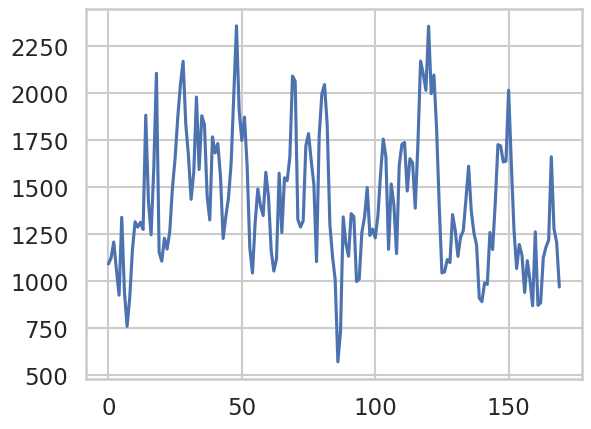

In [ ]:
# plt.plot(E_high)